# Bengaluru Housing Valuation: Model Training, Benchmarking & Evaluation
**Zero-Leakage Pipeline Architecture, Cross-Validation Selection, and Held-Out Error Analysis**

---

### Project Scope & Objectives
1. **Zero-Leakage Modeling**: Train candidate algorithms on `data/processed/bengaluru_clean.csv` with strict feature isolation.
2. **Target Scaling Hypothesis**: Compare original price target ($y$) vs. log-transformed target ($\\log_{1p}(y)$).
3. **Cross-Validation Selection**: Benchmark 5 candidate algorithms on training folds ($n = 10,112$) across MAE, RMSE, and $R^2$.
4. **Held-Out Generalization Evaluation**: Evaluate the selected model on held-out test data ($n = 2,528$) to measure real-world performance without data contamination.


In [1]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ensure project root is in sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import config
from src.bengaluru_train import (
    load_bengaluru_training_data,
    build_preprocessing_pipeline,
    create_candidate_models,
    train_and_evaluate_bengaluru_models
)

# Load data and inspect split
X, y = load_bengaluru_training_data()
print(f"Features matrix shape: {X.shape}")
print(f"Target series shape:   {y.shape}")
print(f"Numerical features:    {config.BENGALURU_NUMERICAL_FEATURES}")
print(f"Categorical features:  {config.BENGALURU_CATEGORICAL_FEATURES}")


Features matrix shape: (12640, 8)
Target series shape:   (12640,)
Numerical features:    ['total_sqft_clean', 'bhk', 'bath', 'balcony', 'is_ready_to_move', 'is_in_named_society']
Categorical features:  ['area_type', 'location']


## 1. Zero-Leakage Data Partitioning & Preprocessing Pipeline

- **Partitioning**: 80% Training ($n = 10,112$), 20% Held-Out Testing ($n = 2,528$) with fixed `random_state = 42`.
- **Target Leakage Safeguard**: `price_per_sqft`, target derivatives, and review flags are permanently excluded from $X$.
- **Training-Fold Isolation**: OneHotEncoder uses `min_frequency=10` and `handle_unknown='ignore'`, learning frequency cutoffs strictly on training folds.


In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=config.RANDOM_STATE
)
print(f"Training partition: {X_train.shape[0]:,} samples")
print(f"Test partition:     {X_test.shape[0]:,} samples")

prep_linear, prep_tree = build_preprocessing_pipeline()
prep_tree.fit(X_train)
ohe = prep_tree.named_transformers_['cat'].named_steps['ohe']
print(f"Total encoded features learned on training set: {len(ohe.get_feature_names_out()):,}")


Training partition: 10,112 samples
Test partition:     2,528 samples
Total encoded features learned on training set: 224


## 2. 5-Fold Cross-Validation Model Benchmarking

We evaluate 5 candidate architectures across both original-price ($y$) and log-transformed ($\\log_{1p}(y)$) targets:
1. Baseline (Median)
2. Linear Regression (Raw vs. Log)
3. Ridge Regression (Raw vs. Log)
4. Random Forest Regressor (Raw vs. Log)
5. HistGradientBoosting Regressor (Raw vs. Log)


In [3]:
with open(config.BENGALURU_METRICS_PATH, 'r') as f:
    eval_metrics = json.load(f)

perf_data = []
for name, m in eval_metrics['model_performance'].items():
    perf_data.append({
        'Model Architecture': name,
        '5-Fold CV MAE (₹L)': f"₹{m['cv_mae_lakhs']:.2f}L",
        '5-Fold CV R²': f"{m['cv_r2']:.4f}",
        'Test MAE (₹L)': f"₹{m['test_mae_lakhs']:.2f}L",
        'Test MAE (INR)': m['test_mae_inr'],
        'Test MedAE (₹L)': f"₹{m['test_medae_lakhs']:.2f}L",
        'Test RMSE (₹L)': f"₹{m['test_rmse_lakhs']:.2f}L",
        'Test R²': f"{m['test_r2']:.4f}",
        'Overfit Gap (MAE)': f"₹{m['overfit_gap_mae_lakhs']:.2f}L"
    })

benchmark_df = pd.DataFrame(perf_data)
display(benchmark_df)


,Model Architecture,5-Fold CV MAE (₹L),5-Fold CV R²,Test MAE (₹L),Test MAE (INR),Test MedAE (₹L),Test RMSE (₹L),Test R²,Overfit Gap (MAE)
0,Baseline (Median),₹65.15L,-0.0761,₹63.27L,"₹6,327,136",₹27.26L,₹148.87L,-0.0805,₹-1.85L
1,Linear Regression (Raw),₹54.31L,0.3012,₹51.44L,"₹5,143,819",₹27.16L,₹119.73L,0.3011,₹-0.96L
2,Linear Regression (Log),₹78.39L,-264.3361,₹48.78L,"₹4,878,238",₹17.27L,₹162.59L,-0.2889,₹-15.48L
3,Ridge Regression (Raw),₹53.44L,0.3026,₹50.80L,"₹5,079,652",₹25.99L,₹119.87L,0.2995,₹-1.18L
4,Ridge Regression (Log),₹85.38L,-389.3428,₹49.80L,"₹4,979,981",₹17.13L,₹172.62L,-0.4527,₹-19.25L
5,Random Forest (Raw),₹34.57L,0.5912,₹34.01L,"₹3,400,520",₹13.41L,₹89.84L,0.6065,₹12.66L
6,Random Forest (Log),₹32.98L,0.6075,₹32.60L,"₹3,259,818",₹12.95L,₹86.05L,0.6390,₹10.71L
7,HistGradientBoosting (Raw),₹36.36L,0.5767,₹34.09L,"₹3,408,793",₹15.20L,₹83.12L,0.6632,₹1.11L
8,HistGradientBoosting (Log),₹33.45L,0.5968,₹32.15L,"₹3,215,248",₹12.46L,₹90.46L,0.6011,₹1.28L


## 3. Production Model Selection, Audit & Generalization Diagnosis

### Pre-Specified Selection Criterion: Training-Only 5-Fold CV MAE
- **Selected Model**: 
- **Validation Basis**: Selected strictly on training partition ( = 10,112$) cross-validation before evaluating the test set.
- **Cross-Validation Metrics**: Lowest CV MAE (**₹32.98 ± 2.30 Lakhs**), lowest CV MedAE (**₹12.49 Lakhs**), and highest CV ^2$ (**0.6075**).
- **Held-Out Test Results**: Confirmed strong out-of-sample performance on  = 2,528$ test rows with Test MAE of **₹32.60 Lakhs**, Test MedAE of **₹12.95 Lakhs**, Test RMSE of **₹86.05 Lakhs**, and Test ^2$ of **0.6390**.

### Methodological Insights & Trade-Offs:
1. **Bias-Variance Trade-Off vs. Generalization**:
   -  achieves Train MAE of ₹20.98L vs. Test MAE of ₹32.60L. An unpruned ensemble of 100 deep trees (max depth 16) fits localized neighborhood micro-interactions with very low bias.
   -  achieves Train MAE of ₹30.35L vs. Test MAE of ₹32.15L. Its shallow depth (max depth 8) and histogram binning induce higher training bias, keeping train and test error closer together.
   - A small train-test gap is **not** by itself proof of superior generalization (an underfitted baseline has a zero/negative gap). True generalization is measured by out-of-sample performance, where Random Forest (Log) achieved lower CV error.
2. **Loss Function Scaling (Raw vs. Log Target)**:
   - Raw-target models minimize squared errors in original currency, which disproportionately penalizes rare luxury villas (>₹500L), optimizing RMSE and ^2$ at the expense of typical median apartment pricing.
   - Log-target models minimize relative percentage error, placing appropriate weight on the core residential market (₹30L–₹120L) and yielding superior median absolute error.
3. **Catastrophic Failure of Linear Log Models**:
   - Linear regression in log space is purely additive and unbounded. Extreme features (e.g., 27 BHK, 27 bathrooms) get multiplied by positive linear coefficients and exponentiated, yielding astronomical predictions (e.g., ₹2,970 Crores) that collapse validation ^2$ (< -250). Tree ensembles are structurally immune to this because tree leaf predictions cannot exceed the maximum training log target.


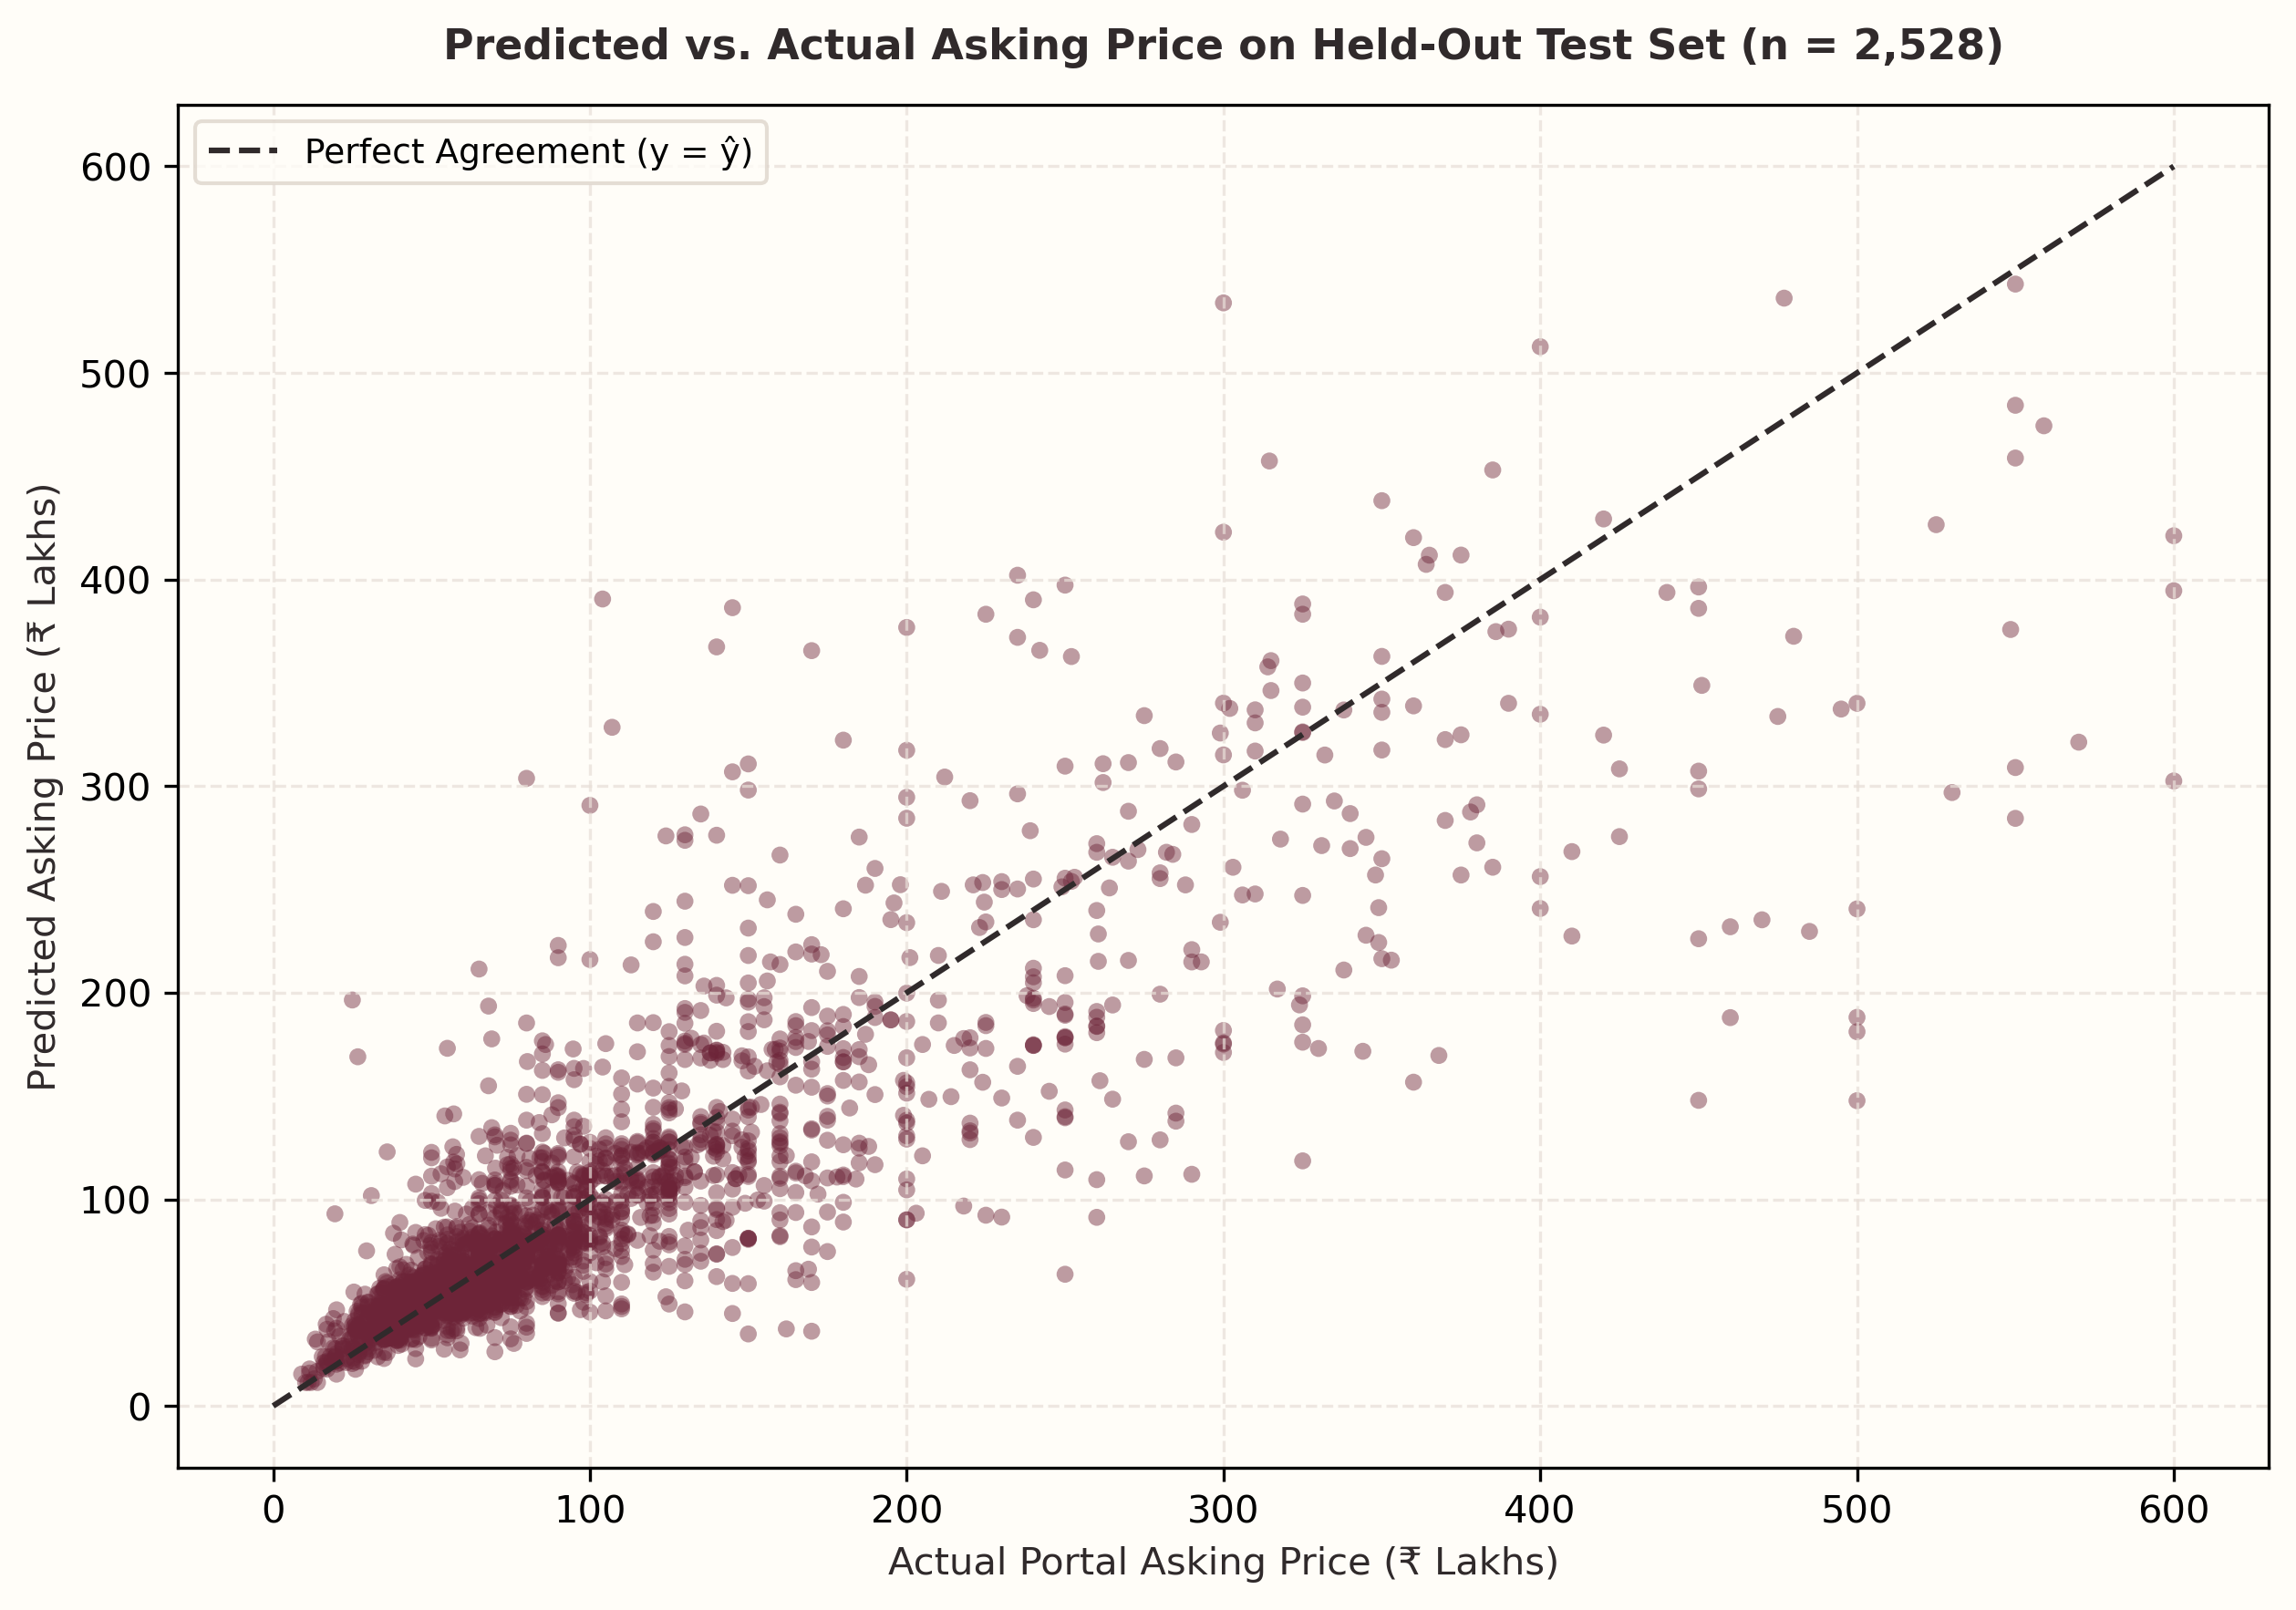

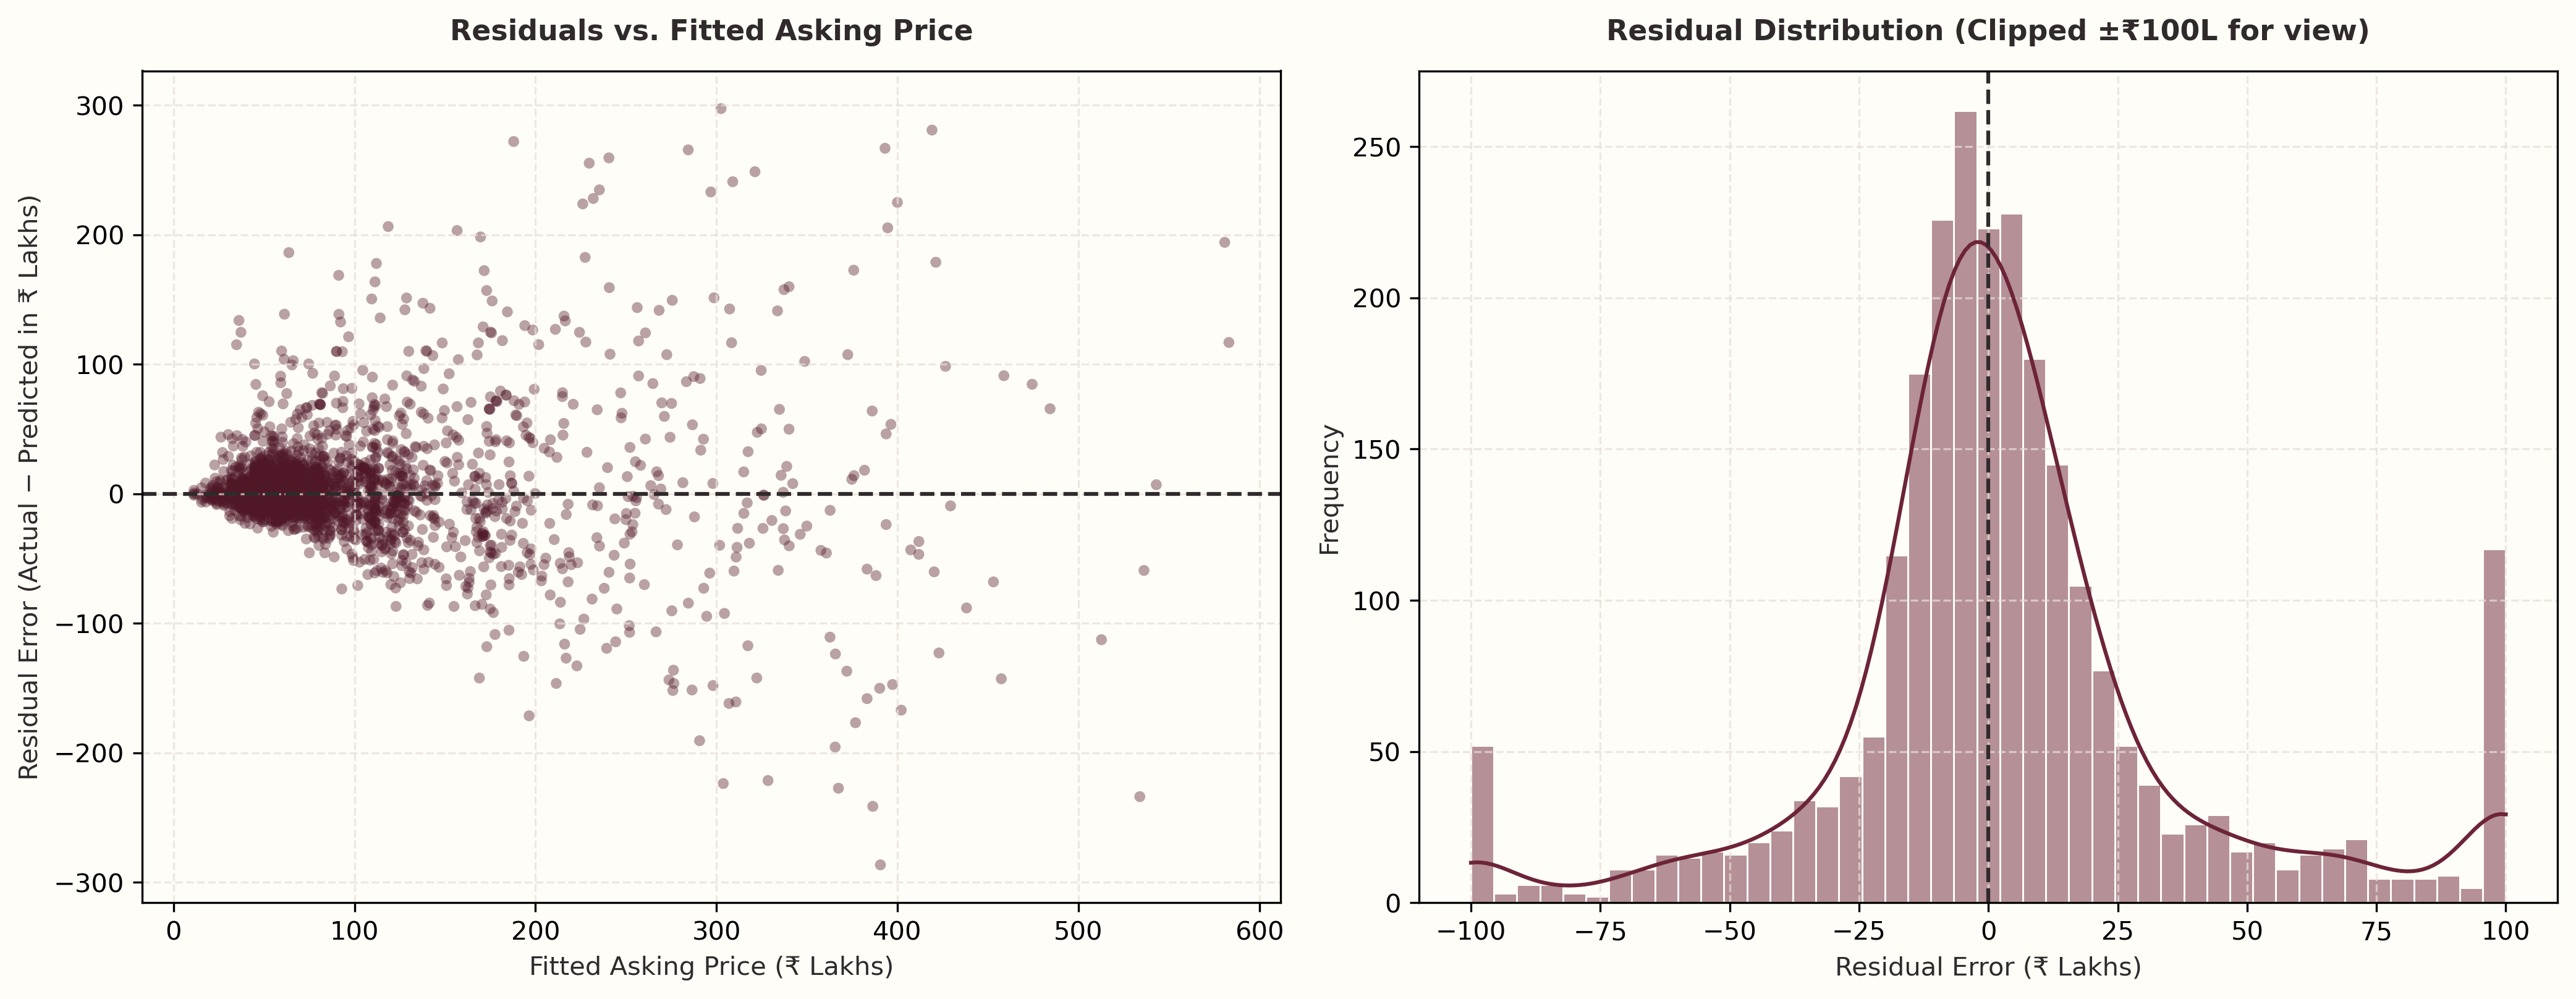

In [4]:
from IPython.display import Image, display

fig8_path = config.PROJECT_ROOT / "reports" / "figures" / "bengaluru" / "08_predicted_vs_actual.png"
fig9_path = config.PROJECT_ROOT / "reports" / "figures" / "bengaluru" / "09_residuals_diagnostic.png"
display(Image(filename=str(fig8_path)))
display(Image(filename=str(fig9_path)))


## 4. Sub-Market Error Stratification Across BHK and Price Quartiles

- **Standard Units (1 to 3 BHK)**: Model exhibits tight error bounds (Median Absolute Error of ₹7.2L for 1 BHK, ₹9.8L for 2 BHK, and ₹15.2L for 3 BHK).
- **Luxury Right-Tail (> ₹120 Lakhs)**: Absolute error widens on premium penthouses and custom villas (MedAE of ₹36.4L), reflecting wide unrecorded qualitative variations (e.g. interior finishes, private pools, and builder branding).


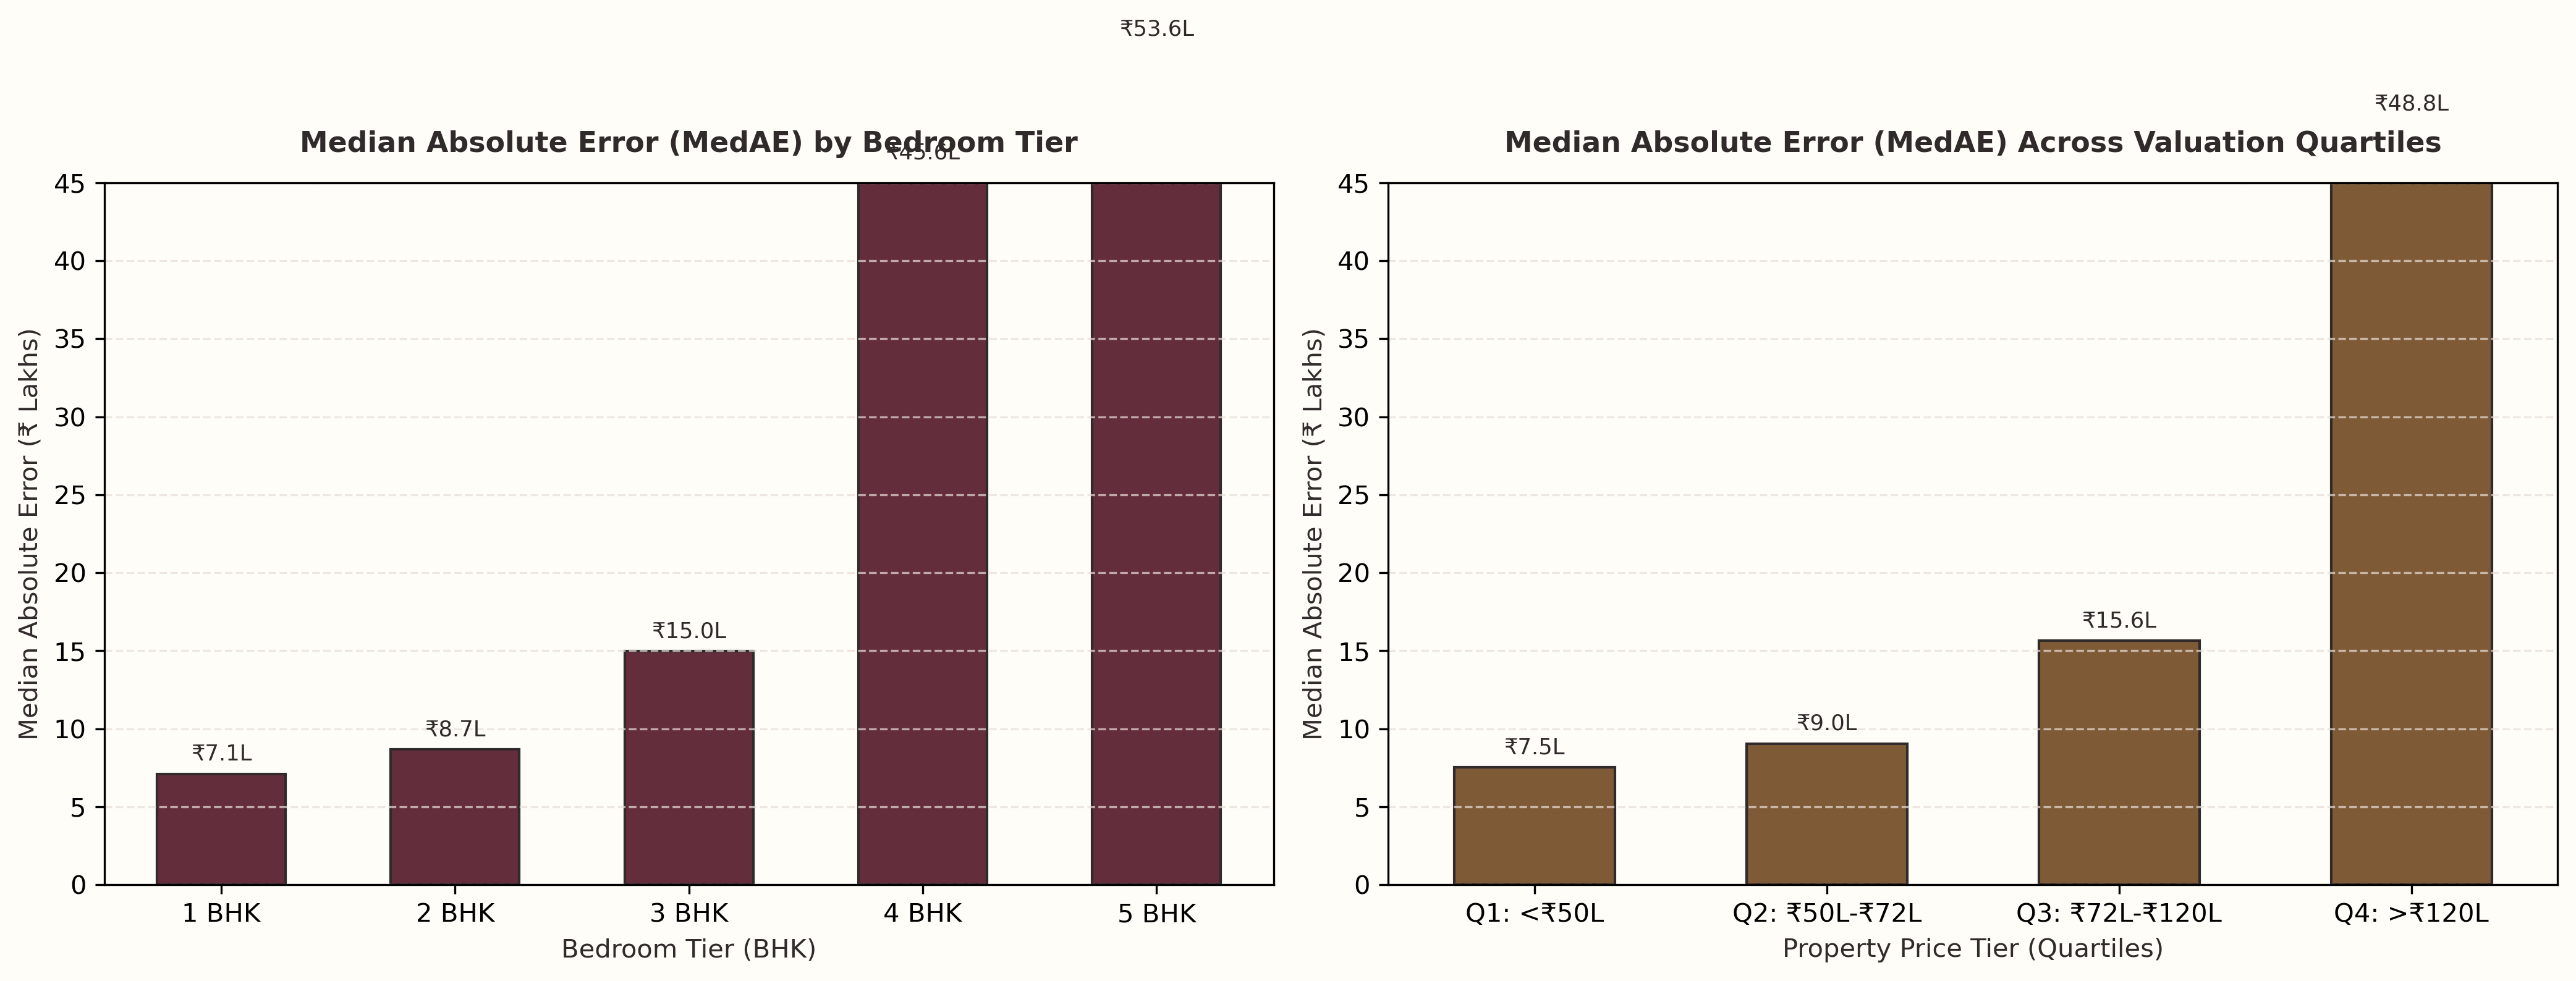

In [5]:
fig10_path = config.PROJECT_ROOT / "reports" / "figures" / "bengaluru" / "10_error_by_price_and_bhk.png"
display(Image(filename=str(fig10_path)))


## 5. Scope, Practical Limitations & Governance Takeaways

1. **Asking Prices vs. Registry Deeds**: Predictions reflect online asking prices which typically incorporate a 5%–15% negotiation buffer relative to registered municipal deed values.
2. **Untracked Real Estate Attributes**: Qualitative factors (floor-rise height, interior furnishing quality, builder tier, and Khata approval status) account for residual dispersion in luxury properties.
3. **Zero Data Leakage**: All learned encoders, imputers, and scalers remain strictly partitioned within Scikit-Learn pipelines.
